In this second practical session, we explore surface deformation algorithms with two applications : surface parametrization for texture mapping and as-rigid-as possible deformation for non-rigid alignment.

Program for today:
1. Surface Parameterisation

    a. Tutte embedding,

    b. Angle-preserving map with free boundary.
    
2. Surface alignment

    a. Rigid alignment with Iterative Closest Point,

    b. ARAP for non-rigid alignment.


# Environment Setup

We simplified the environment installation. Don't forget to comment after running this command once.

In [1]:
#!wget -q https://www.lix.polytechnique.fr/~pierson/cours/td2_utils.zip -O td2_utils.zip
#!unzip -qqo td2_utils.zip

In [2]:
#!pip install -r requirements.txt

In [3]:
import os
import shutil
from scipy.spatial import KDTree
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse.linalg as sla
import scipy.sparse
from scipy.sparse import csc_matrix

# THE FOLLOWING COME FROM THE PROVIDED DATA, DO NOT TRY TO PIP INSTALL THEM
import plot_utils as plu
import meshplot as mp
import mesh_utils
from mesh_utils.mesh import TriMesh

class KNNSearch:
    def __init__(self, data):
        self.tree = KDTree(data)
    def query(self, query_points, k=1):
        _, indices = self.tree.query(query_points, k=k)
        return indices
#We define our own KNNsearch class to avoid importation of sklearn.neighbors.KDTree which is not available in the provided environment.


### Choose your rendering backend. 

Main settings: <b><code style="color:red;">colab</code></b> is if you are in colab, <b><code style="color:red;">server</code></b> if you use a cluster (always true when using colab). The latter needs to have the `xvfb` package installed (automatic in colab). Set up the values correctly!

For those struggling with meshplot, use <b><code style="color:red;">meshplot=False</code></b>

You shouldn't have any problems anymore. However, the interactive windows are replaced by rendering (in different views) of the meshes.

# 1 - Surface Parameterisation

Given a triangle mesh with triangle list $T$ ($n_f \times 3$ array of integers) and vertex coordinates $X$ ($n_v \times 3$ array of floats), a parametrization is simply an assignment of planar coordinates $U$ ($n_v \times 2$ array of floats) for each vertex of the mesh. This parametrization will be vizualized by mapping a texture in planar coordinates to 3D coordinates.

## 1.1 Tutte embedding

The most simple way of computing planar coordinates is to fix the boundary of the mesh to predefined positions (in this example a rectangle) and place the inner vertices at the barycenter of their neighbours. More precisely, the planar coordinates $(u_i,v_i)$ of vertex $i$ satisfies the equation:
$$ \sum_{j \in N_i} w_{ij} (u_j - u_i) = 0, \quad \sum_{j \in N_i} w_{ij} (v_j - v_i) = 0, $$
where $w_{ij}$ are the cotan-weights computed in the previous practical session and $N_i$ is the set of vertices linked to $i$ by an edge. Moreover, for a boundary vertex $j$, the coordinates $(u_j,v_j)$ are constrained to the position $(\bar{u}_j,\bar{v}_j)$.

This system of linear equations can be easily rewritten in term of Laplacian matrix $W$ computed in the previous session:
$$
\begin{array}{l}
W u = 0, \text{ and } W v = 0, \\
u_j = \bar{u}_j, \text{ and } v_j = \bar{v}_j \text{ for all boundary vertex $j$.}
\end{array}
$$

Let `id_int` and `id_bnd` be the lists of interior and boundary indices. The boundary coordinates `u[id_bnd]` and `v[id_bnd]` are given by the function ???.  By linearity, the constrained system reads `W[id_int,id_int]*u[id_int] =-W[id_int,id_bnd]*u[id_bnd]`.

1. Build the lists `id_int` and `id_bnd`
2. Solve the constrained system of linear equations
3. Vizualize the texture

###  QUESTION 1 - Border Edges

**Given a set of triangles, compute the list of (unordered) edges which lie at the border**

Note that we use np.unique in the next cell, so don't overcomplicate the problem.

In [4]:
def get_border_edges(triangles):
    """
    Get the border edges of a mesh. In no particular order

    Parameters
    ----------
    triangles : ndarray of shape (n_triangles, 3)

    Returns
    -------
    border_edges : list of list of length n_border_edges.
                   The border edges of the mesh. Element i contains the two
                     vertices of the i-th border edge. 
    """
    border_edges = []
    # We will use the property that in a 2-variety mesh, an edge can be adjacent to at most two triangles. If it is adjacent to only one triangle, it is a border edge.
    edges = []
    
    e1 = triangles[:, [0, 1]]
    e2 = triangles[:, [1, 2]]
    e3 = triangles[:, [2, 0]]

    raw_edges = np.vstack([e1, e2, e3])
    unique_edges, counts = np.unique(np.sort(raw_edges, axis=1), axis=0, return_counts=True)
    # here we sort the edges so we can count them properly (e.g. edge [1, 2] is the same as edge [2, 1]), and we iterate through every edge (line by line so axis = 0)
    border_edges = unique_edges[counts == 1]
  

    return border_edges

In [5]:
mesh1 = TriMesh('./data/sphere_cut_uv.obj').process(k=0)

border_edges = get_border_edges(mesh1.faces)
# Visualize the border. It is here just a cut of the sphere

# as VTK is not supported on windows, I directly use meshplot to visualize the border edges. 
mp.plot(mesh1.vertices, mesh1.faces, shading={"point_size": 0.15, "highlight": np.unique(border_edges)})

Renderer(camera=PerspectiveCamera(children=(DirectionalLight(color='white', intensity=0.6, position=(0.0, 0.0,…

### Question 2 - Orderd points on a circle

**Write a function to generate evenly spaced points on the circle**
These are going to be the fixed positions of our border vertices

In [6]:
def get_n_points_on_circle(n_points):
    """
    Builds n_points evenly spaced points on the unit circle.

    Parameters
    ----------
    n_points : int
        Number of points to generate

    Returns
    -------
    points : ndarray of shape (n_points, 2)
        The points on the unit circle
    """
    # There we just divide the unit circle in uniformely spaced points 
    indices = np.arange(n_points)
    thetas = indices * (2 * np.pi / n_points)
    (x,y) = np.cos(thetas), np.sin(thetas)
    points = np.stack((x,y), axis=1)


    return points

(np.float64(-1.1),
 np.float64(1.1),
 np.float64(-1.046162167924669),
 np.float64(1.046162167924669))

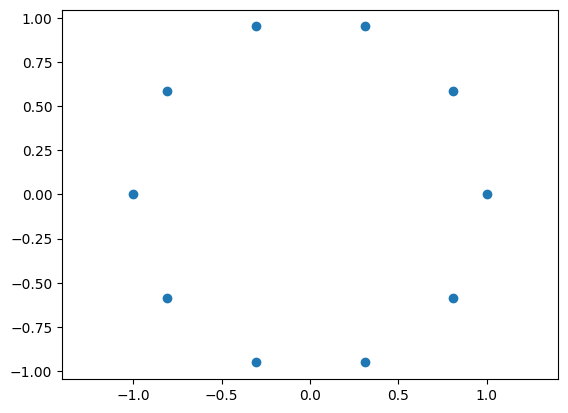

In [7]:
circle_points = get_n_points_on_circle(10)
plt.figure(dpi=100)
plt.scatter(circle_points[:,0], circle_points[:,1])
plt.axis('equal')

### Question 3 - Solving the Embedding

**Solve for the uv coordinate using ```scipy.sparse.linalg.spsolve```**

Tip: To select ```W[id_int,id_int]``` on a sparse matrix ```W[id_int,id_int]```, use ```W[id_int,:][:,id_int]```.

Because your border points are *ordered*, you will need to use an *ordered* list if border edges. We provide a function below which generates an *ordered* list of border edges using your ```get_border_edges``` function from Question 1.

In [8]:
def find_next_edge(current_edge, remaining_edges):
        for i, edge in enumerate(remaining_edges):
            if current_edge[1] in edge:
                return i, edge 
        return None, None

def build_ordered_edges(triangles):
    """
    Compute an ordered list of edges that form a path around the border of the mesh.

    Parameters
    ----------
    triangles : ndarray of shape (n_triangles, 3)

    Returns
    -------
    ordered_edge_list : list of list of length n_border_edges.
                        The border edges of the mesh. Element i contains the two
                        vertices of the i-th border edge.
    """
    
    border_edges = get_border_edges(triangles)  # (p,2)
    remaining_edges = border_edges.tolist()
    current_edge = remaining_edges.pop(0) 
    ordered_edge_list = [current_edge] #Initialize the ordered edge list with the first edge

    while len(remaining_edges) > 0:
        idx, next_edge = find_next_edge(current_edge, remaining_edges)
        
        if next_edge is None:
            break  # 
        if next_edge[0] != current_edge[1]:
             next_edge = next_edge[::-1]  # Reverse the edge if needed (we could have used the code provided and do it directly in the find_next_edge function)
        ordered_edge_list.append(next_edge)
        remaining_edges.pop(idx) #pop the edges of the path until no edge is left
        current_edge = next_edge

    

    return ordered_edge_list     

In [9]:
# Load the mesh and compute the Laplacian
mesh1 = TriMesh('./data/sphere_cut_uv.obj').process(k=0)
uv_map = mesh_utils.read_obj_texture('./data/sphere_cut_uv.obj')[-1]
# Get the list of ordered edges and the Laplacian
ordered_edges = build_ordered_edges(mesh1.faces)
W = mesh1.W

mp.plot(mesh1.vertices, mesh1.faces, uv=uv_map, return_plot=True)


Renderer(camera=PerspectiveCamera(children=(DirectionalLight(color='white', intensity=0.6, position=(0.0, 0.0,…

In [10]:
ordered_edges = build_ordered_edges(mesh1.faces)
id_bnd = np.array([edge[0] for edge in ordered_edges], dtype=int)
all_indices = np.arange(mesh1.n_vertices)
id_int = all_indices[~np.isin(all_indices, id_bnd)] #isin checks whether or not the indices in all_indices are in id_bnd and put True of False accordingly

u = np.zeros(mesh1.n_vertices)
v = np.zeros(mesh1.n_vertices)
print(id_bnd)
positions_cercle = get_n_points_on_circle(len(id_bnd))
u[id_bnd] = positions_cercle[:, 0] #we initialise the boundaries
v[id_bnd] = positions_cercle[:, 1]

W_ii = W[id_int, :][:, id_int]
W_ib = W[id_int, :][:, id_bnd]


rhs_u = -W_ib.dot(u[id_bnd])
rhs_v = -W_ib.dot(v[id_bnd])

u[id_int] = sla.spsolve(W_ii, rhs_u)
v[id_int] = sla.spsolve(W_ii, rhs_v)


uv_int = np.column_stack((u[id_int], v[id_int]))      
uv_total = np.column_stack((u, v))                   

flat_coords = np.zeros((mesh1.n_vertices, 3))
flat_coords[:, :2] = uv_total

[   0    7 2159 2157 2155 2153 2151 2149 2147 2145 2143 2141 2139 2137
 2135 2134   17   26  883  881  879  877  875  873  871  869  867  865
  863  861  859  858   37   39  219  217  215  213  211  209  207  205
  203  201  199  197  195  193   45   44   73   75   78   82   87   93
  100  108  117  127  138  150  163  177  192 1390 1405 1407 1410 1414
 1419 1425 1432 1440 1449 1459 1470 1482 1495 1509 1524 2133 2132 2131
 2130 2129 2128 2127 2126 2125 2124 2123 2122 2121 2120    8]


In [11]:
# Visualize the results
# Flattened coordinates with regular grid
mp.plot(flat_coords, mesh1.faces, uv_total,shading={"wireframe": True}) 

Invalid color array given! Supported are numpy arrays. <class 'numpy.ndarray'>


Renderer(camera=PerspectiveCamera(children=(DirectionalLight(color='white', intensity=0.6, position=(0.0, 0.0,…

In [12]:
# We can take the regular grid back to the sphere
mp.plot(mesh1.vertices, mesh1.faces, uv=uv_map, shading={"wireframe": True})

#Or take the Texture of the sphere to the flat world
mp.plot(flat_coords, mesh1.faces, uv=uv_total, shading={"wireframe": True})

Renderer(camera=PerspectiveCamera(children=(DirectionalLight(color='white', intensity=0.6, position=(0.0, 0.0,…

Renderer(camera=PerspectiveCamera(children=(DirectionalLight(color='white', intensity=0.6, position=(0.0, 0.0,…

Let's now visualize how it would render on the Earth

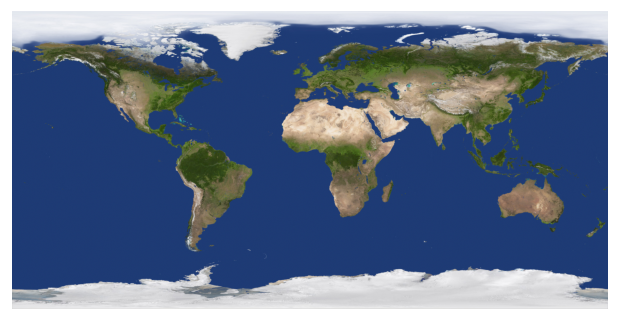

In [13]:
image = plt.imread('data/earth_daymap.jpg') / 255.0
plt.figure(dpi=120)
plt.imshow(image)
plt.axis('off');

In [14]:
mp.plot(mesh1.vertices, mesh1.faces, uv=(uv_total + 1) / 2, texture_data=image, shading={"wireframe": False})

c:\Users\mathy\AppData\Local\Programs\Python\Python314\Lib\site-packages\pythreejs\traits.py:257: UserWarning: 64-bit data types not supported for WebGL data, casting to 32-bit.
  warnings.warn('64-bit data types not supported for WebGL '


Renderer(camera=PerspectiveCamera(children=(DirectionalLight(color='white', intensity=0.6, position=(0.0, 0.0,…

### If you want to visualize it better, save it and load in Meshlab.

In [15]:
os.makedirs('results', exist_ok=True)
shutil.copyfile('data/earth_daymap.jpg', 'results/earth_daymap.jpg')


# THIS EXPORTS A .OBJ FILE WITH TEXTURE AND MATERIAL INFORMATION. DOWNLOAD AND OPEN WITH MESHLAB
TriMesh(flat_coords, mesh1.faces).export_texture('results/tutte_earth.obj', uv_map, texture_im='earth_daymap.jpg')

## 1.2 Least Square Conformal Map

Conformal maps are special type of parametrization which preserves angles and circles. On a smooth surface, they are characterized by the relationship between the gradient of the coordinate $u$ and the coordinate $v$
$$ \nabla u = n \times \nabla v $$
where $n$ is the surface normal. On a triangle mesh, the coordinates $(u,v)$ are computed using a linear least-squares problem
$$ \min_{u,v} \sum_{t \in T} A_t |\nabla u - n \times \nabla v|^2 \text{ subject to the constraint: } \sum_i u_i^2 + v_i^2 = 1 $$
where $A_t$ is the area of triangle $t$. As explained in the course, the objective function can be written in term of the Laplacian matrix $W$. This leads to the smallest eigenvalue problem
$$ \min_{u,v} \begin{pmatrix} u \\ v \end{pmatrix}^\top \begin{pmatrix} W & -M \\ -M^\top & W \end{pmatrix} \begin{pmatrix} u & v \end{pmatrix} \text{ subject to the constraint: } \sum_i u_i^2 + v_i^2 = 1 $$
The sparse matrix $M$ of size $n_v \times n_v$ is given by
$$ M_{ij} = \begin{array}{ll} 
0 & \text{if $i$ or $j$ is an interior vertex } \\
1/2 & \text{if $i$ to $j$ is a positive edge of the boundary triangle} \\
-1/2 & \text{if $i$ to $j$ is a negative edge of the boundary triangle} 
\end{array} $$

Positive edges are edges that appear when going around a face in the order provided in the file. Negative edges are when going the opposite direction.

*Tips:* To assemble this matrix simply accumulate $\pm\frac{1}{2}$ values for all triangles using the triangle list using the formula above. Since interior edges appear twice in opposite direction in the mesh, their coefficient will vanish for them, and only values for border edges will remin


1. Build the sparse matrix `M`
2. Compute the LSCM parametrization using `scipy.sparse.linalg.eigs` 
3. Extract the boundary coordinate of the parametrization and use them to compute a Tutte embedding 

### Question 4 - Build M

In [16]:
def build_M(faces):
    """
    Build the M matrix above with values only at border edges.
    M can be build by adding the formula for M_ij for each edge of each face on the mesh.
    Coefficients at interior edges will vanish because they appear twice with opposite signs.

    Parameters
    ----------
    faces : ndarray of shape (n_faces, 3)

    Returns
    -------
    M : scipy.sparse.csr_matrix of shape (n_vertices, n_vertices)
    """

    ordered_edges = build_ordered_edges(faces)
    M = scipy.sparse.lil_matrix((faces.max() + 1, faces.max() + 1))
    for i, j in ordered_edges:
        M[i, j] = 1/2
        M[j, i] = -1/2  
    return M    

### Question 5 - Solve the system

Use scipy [bmat function](https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.bmat.html) to build sparse matrices from blocks.
Use scipy

Try with the two meshes (diablo doesn't have uv map)

In [17]:
#mesh1 = TriMesh("./data/diablo_cut2.obj").process(k=0)
mesh1 = TriMesh("./data/sphere_cut_uv.obj").process(k=0)
uv_map = v,f,uv_map = mesh_utils.read_obj_texture('./data/sphere_cut_uv.obj')
W = mesh1.W

In [18]:
M = build_M(mesh1.faces)

system_matrix = scipy.sparse.bmat([[W, -M], [-M.T, W]], format='csr')

res_eigenvalues, res_eigenvectors = scipy.sparse.linalg.eigsh(system_matrix, k=3, which='LM', sigma=-0.001)

# Only take the real part

# Check that first 2 eigenvalues are 0
#res_eigenvalues[np.abs(res_eigenvalues) < 1e-11] = 0.0 #We can set set the eigenvalues to exactly if we want zero because we have 10^-16 which is 0 in computer science. 
print(res_eigenvalues)

[-1.27068495e-16 -1.17310675e-16  1.32033361e-05]


In [19]:
uv_coords = res_eigenvectors[:,2].reshape((mesh1.n_vertices,2), order='F')

mp.plot(mesh1.vertices, mesh1.faces, uv_coords)

#plu.plot_texture(flat_coords, mesh1.faces, flat_coords)


# For the Sphere
#plu.plot_texture(flat_coords, mesh1.faces, uv_map, wireframe=True)

Invalid color array given! Supported are numpy arrays. <class 'numpy.ndarray'>


Renderer(camera=PerspectiveCamera(children=(DirectionalLight(color='white', intensity=0.6, position=(0.0, 0.0,…

you can again visualize with the earth map on the sphere

In [20]:
mp.plot(mesh1.vertices, mesh1.faces, uv_coords, texture_data=image, shading={"wireframe": False})

Invalid color array given! Supported are numpy arrays. <class 'numpy.ndarray'>


Renderer(camera=PerspectiveCamera(children=(DirectionalLight(color='white', intensity=0.6, position=(0.0, 0.0,…

In [21]:
flat_coords =  np.zeros((mesh1.n_vertices,3))
flat_coords[:,:2] = uv_total
TriMesh(flat_coords, mesh1.faces).export_texture('results/lscm_earth.obj', uv_coords, texture_im='earth_daymap.jpg')

###  Question 6 - Extract the Border and compute the tutte embedding on the same border (with ordering)

In [22]:
sol = res_eigenvectors[:, 2]
n_v = mesh1.vertices.shape[0]
uv_lscm = np.column_stack((sol[:n_v], sol[n_v:]))

id_bnd = [edg[0] for edg in ordered_edges]
id_int = np.setdiff1d(np.arange(n_v), id_bnd)

uv_bnd = uv_lscm[id_bnd]
uv_int = scipy.sparse.linalg.spsolve(W_ii, -W_ib @ uv_bnd)

uv_tutte_2 = np.zeros((n_v, 2))
uv_tutte_2[id_bnd] = uv_bnd
uv_tutte_2[id_int] = uv_int

# Visualisation des résultats
flat_coords = np.zeros((mesh1.vertices.shape[0], 3))
flat_coords[:, :2] = uv_tutte_2
print(np.linalg.norm(uv_tutte_2 - uv_coords))

0.00077233698683023


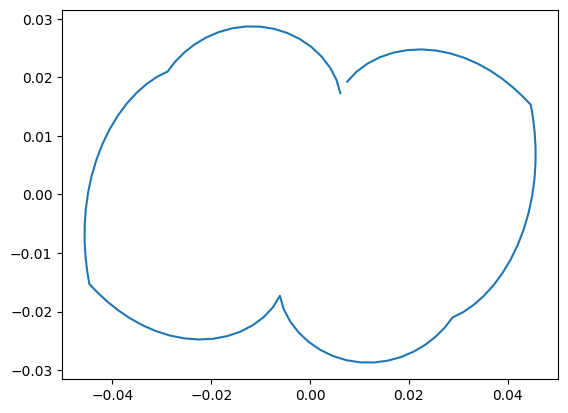

In [23]:
plt.plot(uv_bnd[:, 0], uv_bnd[:, 1]) # Just a check: we plot to verify that the border is continuous

In [24]:
mp.plot(flat_coords, mesh1.faces, uv_tutte_2, shading={"wireframe": True}) 

Invalid color array given! Supported are numpy arrays. <class 'numpy.ndarray'>


Renderer(camera=PerspectiveCamera(children=(DirectionalLight(color='white', intensity=0.6, position=(1.8607825…

In [25]:
mp.plot(mesh1.vertices, mesh1.faces, uv_tutte_2, shading={"wireframe": True}) 

Invalid color array given! Supported are numpy arrays. <class 'numpy.ndarray'>


Renderer(camera=PerspectiveCamera(children=(DirectionalLight(color='white', intensity=0.6, position=(0.0, 0.0,…

# 2 Surface Alignment

## 2.1 Iterative Closest Point

The goal of this algorithm is to align two point clouds $X = \{ x_i \}$ and $Y = \{ y_i \}$ using only rigid transformations -- translation and rotation. It is standard algorithm to align 3D scans taken from different viewpoints. The most basic implementation iterates between three steps until convergence:

1. For each point of $X$ compute the closest point in the set $Y$. This assignment is given by the table $p$
$$ p_i = \arg\min_{j} \|x_i - y_j\|^2 .$$
This can be done efficiently with a knn-search.

2. Find the translation that best align the point cloud given the assignment $p$
$$ \min_{t \in \mathbb{R}^3} \sum_i \|x_i + t - y_{p_i}\|^2 .$$
This problem can be solved exactly with the formula $t = \frac{1}{|X|}\sum_i y_i - x_i$.

3. Compute the rotation aligning the point cloud after translation:
$$ \min_{R} \sum_i \|Rx_i + t - y_{p_i}\|^2 .$$
This is an [orthogonal Procrustes problem](https://en.wikipedia.org/wiki/Orthogonal_Procrustes_problem) and can be solved efficiently using a Singular Value Decomposition ([SVD](https://en.wikipedia.org/wiki/Singular_value_decomposition)). Let the matrix $A = \sum_i (t-y_{p_i})x_i^\top$ be decomposed as $A = U S V^\top$ where $U,V$ are unitary matrices and $S$ a diagonal matrix. The optimal rotation is given by $R = U D V^\top$ with $D$ a diagonal matrix with $+1$ on the diagonal corresponding to the two largest singular values and $\pm 1$ on the smallest singular value. The sign is chosen so that $\det R = 1$.

4. Update the position of $X$: $x_i \leftarrow Rx_i+t$


**To do:**
1. Implement the steps
2. Align the Armadilo

### Question 7 - Compute Nearest Neighbor

To speed up computation, use `scipy.spatial.cKDTree`.

In [26]:
import numpy as np

def compute_nearest_neighbor(X, Y):
    """
    Compute the nearest neighbor in Y for each point in X

    Parameters:
    -----------
    X : (n, d) array of points
    Y : (m, d) array of points

    Returns:
    --------
    nearest_neighbor : (n,) array of indices of the nearest neighbor in Y for X
    """
    # Build the search structure on the reference set Y
    querier = KNNSearch(Y)
    
    # Query each point in X to find its closest neighbor in Y
    nearest_neighbor = querier.query(X, 1)
    
    # Return the array of indices of shape (n,)
    return np.atleast_1d(nearest_neighbor).flatten()

### Question 8 - Compute optimal rotations and translation

In [27]:
def compute_rigid_transform(X_source, X_target):
    """
    Compute the optimal rotation matrix and translation that aligns two point clouds of the same size X_source and X_target.
    This rotation should be applied to X_source.

    Parameters:
    -----------
    X_source : (n, d) array of points
    X_target : (n, d) array of points

    Returns:
    --------
    R : (d, d) rotation matrix
    t : (d,) translation vector
    """
    
    centroid_source = np.mean(X_source, axis=0)
    centroid_target = np.mean(X_target, axis=0)

   
    X_centered = X_source - centroid_source
    Y_centered = X_target - centroid_target

   
    H = X_centered.T @ Y_centered


    U, S, Vt = np.linalg.svd(H)


    V = Vt.T
    d = X_source.shape[1]
    

    D = np.eye(d)
    D[-1, -1] = np.linalg.det(V @ U.T)

    R = V @ D @ U.T

  
    t = centroid_target - R @ centroid_source

    return R, t

### Question 9 - Apply the ICP algorithm
We provide a function to apply a rigid transformation ```R,t``` to a point cloud

In [28]:
def transform_pointcloud(X,R,t):
    """
    Transform a point cloud X by a rotation matrix R and a translation vector t.

    Parameters:
    -----------
    X : (n, d) array of points
    R : (d, d) rotation matrix
    t : (d,) translation vector

    Returns:
    --------
    X_transformed : (n, d) array of transformed points
    """
    return X @ R.T + t

In [29]:
def icp_align(X_source, Y_target, n_iter=10):
    """
    Align two point clouds X_source and Y_target using the ICP algorithm.

    Parameters:
    -----------
    X_source : (n, d) array of points
    Y_target : (m, d) array of points
    n_iter   : int - number of iterations of the ICP algorithm

    Returns:
    --------
    X_aligned : (n, d) array of aligned points
    """
    X_aligned = X_source.copy()
    for i in range(n_iter):
        # Find the nearest neighbors in Y_target for each point in X_aligned
        nearest_neighbors = compute_nearest_neighbor(X_aligned, Y_target)
        
        # Compute the rigid transform to align X_aligned with the nearest neighbors
        R, t = compute_rigid_transform(X_aligned, Y_target[nearest_neighbors])
        
        # Apply the rigid transform to X_aligned
        X_aligned = (R @ X_aligned.T + t.reshape(-1, 1)).T

    return X_aligned

In [30]:
def plot_superimposed(mesh1, mesh2, color_1=[139, 0, 139], color_2=[210, 105, 30], *args, **kwargs):
    """
    Plot the superposition of the two meshes
    """
    #2B7FFF#2B7FFF
    if mp:
        cmap_1 = np.ones(mesh1.vertices.shape)*np.array(color_1)/255.
        cmap_2 = np.ones(mesh2.vertices.shape)*np.array(color_2)/255.
    else:
        cmap_1 = np.ones(mesh1.vertices.shape)*np.array(color_1)
        cmap_2 = np.ones(mesh2.vertices.shape)*np.array(color_2)
    cmap = np.concatenate([cmap_1, cmap_2], axis=0)
    mesh = TriMesh(np.concatenate([mesh1.vertices, mesh2.vertices], axis=0),
                   np.concatenate([mesh1.faces, mesh2.faces+mesh1.n_vertices], axis=0)).process(k=0)
    
    return mp.plot(mesh.vertices, mesh.faces, c=cmap, *args, **kwargs, shading={"flat": False})

mesh1 = TriMesh("./data/Armadillo_1.off")
mesh2 = TriMesh("./data/Armadillo_2.off")

plot_superimposed(mesh1, mesh2)

Renderer(camera=PerspectiveCamera(children=(DirectionalLight(color='white', intensity=0.6, position=(0.5006730…

In [31]:
# VISUALIZE ICP Result
vert1_aligned = icp_align(mesh1.vertices, mesh2.vertices, n_iter=10)

plot_superimposed(TriMesh(vert1_aligned, mesh1.faces), mesh2)

Renderer(camera=PerspectiveCamera(children=(DirectionalLight(color='white', intensity=0.6, position=(0.5234178…

## As-rigid-as possible deformation

This model of  <a href=\"https://igl.ethz.ch/projects/ARAP/arap_web.pdf\">deformation</a> tries to preserves at best the shape features. As explained in the course, given a triangle mesh ($T$: triangle list, $X$: vertex positions) the goal is to find new vertex positions $Y = \\{ y_i\\}$ which are as-close-as possible to a local rotation of the initial position $X$. More precisely, we store a rotation matrix $R_i$ at each vertex $i$ and find the rotations $R$ and position $y$ minimizing\n",

$$ \min_{y,R} \sum_{i} \sum_{j \in N_i} w_{ij} \| y_i - y_j - R_i (x_i - x_j) \|^2, \text{  $y$ subject to position constraint,}$$

with $w_{ij}$ the cotan-weight and $N_i$ the set of vertices adajcent to $i$.
To solve this problem, we iterate between solving for best the position and for rotations.
1. Finding the optimal position $y$ is a constrained Laplacian problem (just like the first question)
$$ W y = b, \quad \text{where } b_i = \sum_{j \in N_i} \frac{w_{ij}}{2} (R_i+R_j) (x_i - x_j) \text{ for each vertex $i$}, $$
and $y$ is constrained at some given vertices.
2. Finding the optimal rotation $R_i$ amounts for solving an orthogonal Procrustes problem for each vertex $i$ where the matrix $B_i = \sum_{j \in N_i} w_{ij} (y_i - y_j) (x_i - x_j)^\top$ is decomposed via a SVD (see step 3 of previous question).

**To do:**
1. Provide functions to compute the initial rotations. This is divided into two subproblems: estimating the covariance, and then computing the rotations using SVD.
2. Fill the function to compute the right side of the optimization
3. Write the optimization loop with the system inside. It consists of alternating between computing b with estimated positions, and solving for new positions.

We provide a function to compute a list of neighbors for each vertex

In [32]:
def get_per_vertex_neighbors(faces):
    """
    Compute per-vertex neighbors from a list of triangles

    Parameters:
    -----------
    faces : (n, 3) array of vertex indices for each triangle

    Returns:
    --------
    neighbors : list of lists of vertex indices
    """

    neighbors = [set() for _ in range(faces.max()+1)]
    for face in faces:
        neighbors[face[0]].add(face[1])
        neighbors[face[0]].add(face[2])

        neighbors[face[1]].add(face[0])
        neighbors[face[1]].add(face[2])

        neighbors[face[2]].add(face[0])
        neighbors[face[2]].add(face[1])

    return [list(n) for n in neighbors]

### Question 10 - Compute the covariance (Matrix B_i)

In [33]:
import numpy as np

def get_arap_edge_covariance(x, y, cotan_matrix, per_vertex_neighbors):
    """
    Compute the covariance matrix B_i for each vertex i.

    Parameters:
    -----------
    x : (n, 3) array of initial coordinates
    y : (n, 3) array of deformed coordinates
    cotan_matrix : (n, n) scipy sparse cotan weight matrix
    per_vertex_neighbors : list of lists, indices of neighbors for each vertex

    Returns:
    --------
    covariances : (n, 3, 3) covariance matrices B_i for each vertex
    """
    n = x.shape[0]
    covariances = np.zeros((n, 3, 3))

    for i in range(n):
        # For each neighbor j of i
        for j in per_vertex_neighbors[i]:
            w_ij = cotan_matrix[i, j]
            
            # Edge differences
            e_ij_deformed = (y[i] - y[j]).reshape(3, 1)  # (y_i - y_j) as column vector (3, 1)
            e_ij_initial = (x[i] - x[j]).reshape(1, 3)   # (x_i - x_j)^T as row vector (1, 3)
            
            # Outer product weighted by the cotangent weight
            covariances[i] += w_ij * (e_ij_deformed @ e_ij_initial)

    return covariances

### Question 11 - Compute Rotations from Covariance (compute R_i)

In [34]:
def get_rot_from_covariances(covariances):
    """
    Compute optimal rotation matrix from edge covariance matrices, using SVD.

    Parameters:
    -----------
    covariances : (n, 3, 3) covariance matrices for each vertex

    Returns:
    --------
    rots : (n, 3, 3) rotation matrices for each vertex
    """
    n = covariances.shape[0]
    rots = np.zeros((n, 3, 3))

    for i in range(n):
        
        # B_i = U @ S @ Vt
        U, S, Vt = np.linalg.svd(covariances[i])
        
        V = Vt.T
        
        D = np.eye(3)
        D[2, 2] = np.linalg.det(V @ U.T)
        
        rots[i] = V @ D @ U.T

    return rots

### Question 12 - Compute Rotated vertices (vector b_i)

In [35]:
import numpy as np

def compute_ARAP_rotated_vert(vertices, rotations, cotan_matrix, per_vertex_neighbors):
    """
    Compute the right hand term of the ARAP linear system (formula b_i)

    Parameters:
    -----------
    vertices : (n, 3) array of vertices (initial positions x)
    rotations : (n, 3, 3) array of rotation matrices R
    cotan_matrix : (n, n) cotan matrix of the mesh
    per_vertex_neighbors : (n,) list with list of neighbors of each vertex

    Returns:
    --------
    b : (n, 3) right hand term of the ARAP linear system
    """
    n = vertices.shape[0]
    b = np.zeros((n, 3))

    for i in range(n):
        for j in per_vertex_neighbors[i]:
            w_ij = cotan_matrix[i, j]
            
            # Cotangent weight divided by 2: w_ij / 2
            weight = w_ij / 2.0
            
            # Sum of applicable rotations: (R_i + R_j)
            R_sum = rotations[i] + rotations[j]
            
            # Initial edge vector: (x_i - x_j)
            edge_initial = vertices[i] - vertices[j]
            
            # Accumulation: (w_ij / 2) * (R_i + R_j) @ (x_i - x_j)
            b[i] += weight * (R_sum @ edge_initial)

    return b

### Question 13 - Apply ARAP Deformation.

We first load the mesh and visualize it with the objective landmark deformation.

In [36]:
mesh3 = TriMesh("data/cactus.off").process(k=0)

# THE ID OF THE LANDMARKS
id_mouv = [1756, 1298, 1663, 118, 637, 1842]
id_lock = id_mouv
# THE EXPECTED POSITIONS OF THE LANDMARKS AFTER OPTIMIZATION
disp = np.array([[0,-0.25,-0.46], [0,-0.4,-0.3], [0,-0.55, -0.], [0, -0.08, -0.05], [0, -0.08, -0.05], [0, 0, 0]])
positions_target = mesh3.vertices[id_lock] + disp

In [37]:
np.tile(np.arange(len(id_lock)),2)

array([0, 1, 2, 3, 4, 5, 0, 1, 2, 3, 4, 5])

In [38]:
# 1. Display the base mesh
p = mp.plot(mesh3.vertices, mesh3.faces)

# 2. Concatenate point positions (fixed/locked points + targets)
points = np.concatenate([mesh3.vertices[id_lock], positions_target])

# 3. Colors associated with the points
cmap_p = np.tile(np.arange(len(id_lock)), 2)

# 4. Add the points on top with shading for size
p.add_points(points, c=cmap_p, shading={"point_size": 0.05})

Renderer(camera=PerspectiveCamera(children=(DirectionalLight(color='white', intensity=0.6, position=(0.5001154…

1

### ARAP Loop

Write the ARAP loop by filling in the blanks

In [39]:
import scipy.sparse.linalg

vertex_neighbors = get_per_vertex_neighbors(mesh3.faces)
n_arap_loop = 5
W = mesh3.W.copy()


id_lock = list(id_lock) #list
id_in = [i for i in range(mesh3.n_vertices) if i not in id_lock]

y_lock = positions_target  #(len(id_lock), 3)

init_res = mesh3.vertices.copy()
init_res[id_lock] = y_lock  #Constraints are set to the target positions

L_in = W[id_in, :][:, id_in]
L_lock = W[id_in, :][:, id_lock]

for k in range(n_arap_loop):
    # Computation of covariances B_i and rotations R_i
    covariances = get_arap_edge_covariance(mesh3.vertices, init_res, W, vertex_neighbors)
    rotations = get_rot_from_covariances(covariances)
    
    b_term = compute_ARAP_rotated_vert(mesh3.vertices, rotations, W, vertex_neighbors)
    
    lhs = L_in
    
    rhs = b_term[id_in] - L_lock @ y_lock
    
    res_in = scipy.sparse.linalg.spsolve(lhs, rhs)
    
    init_res[id_in] = res_in
    init_res[id_lock] = y_lock

In [40]:
last_mesh = TriMesh(init_res, mesh3.faces)

In [41]:
#Visualisation of the final result
p = plot_superimposed(last_mesh, mesh3)

#Prepare the landmarks and their colors
points = np.concatenate([mesh3.vertices[id_lock], positions_target])
cmap_p = np.tile(np.arange(len(id_lock)), 2)

#Add the points on top with add_points and shading for size
p.add_points(points, c=cmap_p, shading={"point_size": 0.03})

Renderer(camera=PerspectiveCamera(children=(DirectionalLight(color='white', intensity=0.6, position=(0.5048071…

1

### Question 15: Write a non-rigid registration algorithm

Now that you have a non-rigid deformation model, make a non-rigid icp function such that it does:

1. Compute approximate spatial nearest neighbor
2. Use this as a guess for ARAP and compute ARAP deformation
3. Updates the approximate spatial guess

Finally, plot the registration. All main functions are ready, it's time to write a bit on your own.

In [42]:
import scipy.sparse
import scipy.sparse.linalg
import numpy as np

def non_rigid_icp(source_mesh, target_vertices, id_lock, n_icp_iter=5, n_arap_iter=3):
    """
    Non-Rigid ICP alignment using ARAP deformation.

    Parameters:
    -----------
    source_mesh : TriMesh, the source mesh to deform
    target_vertices : (m, 3) array, target point cloud/vertices
    id_lock : list/array of vertex indices used as landmarks/constraints
    n_icp_iter : int, number of outer non-rigid ICP iterations
    n_arap_iter : int, number of inner ARAP optimization iterations per step

    Returns:
    --------
    deformed_vertices : (n, 3) array of aligned source vertices
    """
    # Preparation of mesh and topology
    X_curr = source_mesh.vertices.copy()
    W = source_mesh.W.copy()
    vertex_neighbors = get_per_vertex_neighbors(source_mesh.faces)
    
    # Internal vs constrained indices
    id_lock = list(id_lock)
    id_in = [i for i in range(source_mesh.n_vertices) if i not in id_lock]
    
    # Block-split Laplacian matrix for ARAP resolution
    L_in = W[id_in, :][:, id_in]
    L_lock = W[id_in, :][:, id_lock]

    for icp_step in range(n_icp_iter):
        # 1. ICP Step: Find nearest neighbors in target for the landmarks (or source vertices)
        # Update target positions 'y_lock' for the id_lock constraints
        nearest_indices = compute_nearest_neighbor(X_curr[id_lock], target_vertices)
        y_lock = target_vertices[nearest_indices]

        # 2. ARAP Step: Optimization of non-rigid deformation
        for arap_step in range(n_arap_iter):
            # a. Compute covariances B_i and local rotations R_i
            covariances = get_arap_edge_covariance(source_mesh.vertices, X_curr, W, vertex_neighbors)
            rotations = get_rot_from_covariances(covariances)
            
            # b. Rotational right-hand side term b_term
            b_term = compute_ARAP_rotated_vert(source_mesh.vertices, rotations, W, vertex_neighbors)
            
            # c. Solve the constrained system (L_in * y_in = b_in - L_lock * y_lock)
            rhs = b_term[id_in] - L_lock @ y_lock
            res_in = scipy.sparse.linalg.spsolve(L_in, rhs)
            
            # d. Update vertex positions
            X_curr[id_in] = res_in
            X_curr[id_lock] = y_lock

    return X_curr

In [43]:

def compute_cotan_laplacian(vertices, faces):
    """Compute the Laplacian matrix with cotangent weights."""
    num_verts = len(vertices)
    
    i0, i1, i2 = faces[:, 0], faces[:, 1], faces[:, 2]
    v0, v1, v2 = vertices[i0], vertices[i1], vertices[i2]
    
    e0 = v2 - v1
    e1 = v0 - v2
    e2 = v1 - v0
    
    def cotan(a, b):
        cross = np.linalg.norm(np.cross(a, b), axis=1)
        cross[cross < 1e-10] = 1e-10
        dot = np.einsum('ij,ij->i', a, b)
        return dot / cross

    cot0 = cotan(-e1, e2) / 2.0
    cot1 = cotan(-e2, e0) / 2.0
    cot2 = cotan(-e0, e1) / 2.0
    
    I = np.concatenate([i1, i2, i2, i0, i0, i1])
    J = np.concatenate([i2, i1, i0, i2, i1, i0])
    W_val = np.concatenate([cot0, cot0, cot1, cot1, cot2, cot2])
    
    W = scipy.sparse.coo_matrix((W_val, (I, J)), shape=(num_verts, num_verts)).tocsr()
    diag_vals = np.array(W.sum(axis=1)).flatten()
    W = W - scipy.sparse.diags(diag_vals)
    
    return W

# ------------------------------------------------------------------
# 2. Fonction Non-Rigid ICP (Standard et optimisée par factorisation LU)
# ------------------------------------------------------------------
def non_rigid_icp(source_mesh, target_vertices, id_lock, n_icp_iter=10, n_arap_iter=3):
    X_curr = source_mesh.vertices.copy()
    W = source_mesh.W.copy()
    vertex_neighbors = get_per_vertex_neighbors(source_mesh.faces)
    
    id_lock = list(id_lock)
    id_in = [i for i in range(source_mesh.n_vertices) if i not in id_lock]
    
    # Block-split Laplacian matrix
    L_in = W[id_in, :][:, id_in]
    L_lock = W[id_in, :][:, id_lock]

    # Résolution creuse optimisée (évite les lenteurs)
    solve_lu = scipy.sparse.linalg.factorized(L_in)

    for icp_step in range(n_icp_iter):
        # 1. ICP Step : Recherche des plus proches voisins sur la cible
        nearest_indices = compute_nearest_neighbor(X_curr[id_lock], target_vertices)
        y_lock = target_vertices[nearest_indices]

        # 2. ARAP Step : Optimisation locale de la déformation
        for arap_step in range(n_arap_iter):
            covariances = get_arap_edge_covariance(source_mesh.vertices, X_curr, W, vertex_neighbors)
            rotations = get_rot_from_covariances(covariances)
            b_term = compute_ARAP_rotated_vert(source_mesh.vertices, rotations, W, vertex_neighbors)
            
            rhs = b_term[id_in] - L_lock @ y_lock
            res_in = solve_lu(rhs)
            
            X_curr[id_in] = res_in
            X_curr[id_lock] = y_lock

    return X_curr

# ------------------------------------------------------------------
# 3. Exécution Standard du TP
# ------------------------------------------------------------------

# Étape A : Calcul et assignation du Laplacien sur mesh1
W = compute_cotan_laplacian(mesh1.vertices, mesh1.faces)
mesh1.W = W

# Étape B : Lancement direct de l'ICP non-rigide (sans rotation forcée)
non_rigid_aligned_verts = non_rigid_icp(
    source_mesh=mesh1, 
    target_vertices=mesh2.vertices, 
    id_lock=id_lock, 
    n_icp_iter=10, 
    n_arap_iter=3
)

# Étape C : Création du maillage de résultat et visualisation
non_rigid_mesh = TriMesh(non_rigid_aligned_verts, mesh1.faces)
p = plot_superimposed(non_rigid_mesh, mesh2)

# Étape D : Affichage des correspondances (landmarks)
nn_indices = compute_nearest_neighbor(non_rigid_aligned_verts[id_lock], mesh2.vertices)
points_corr = np.vstack([non_rigid_aligned_verts[id_lock], mesh2.vertices[nn_indices]])

p.add_points(
    points_corr, 
    c=np.tile(np.arange(len(id_lock)), 2), 
    shading={"point_size": 0.03}
)

c:\Users\mathy\AppData\Local\Programs\Python\Python314\Lib\site-packages\scipy\sparse\linalg\_dsolve\linsolve.py:606: SparseEfficiencyWarning: splu converted its input to CSC format
  return splu(A).solve


Renderer(camera=PerspectiveCamera(children=(DirectionalLight(color='white', intensity=0.6, position=(0.5099472…

1